In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [112]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [113]:
df = pd.read_csv('/content/smartphones.csv')

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
                                     Smartphone     Brand           Model  \
0            Realme C55 8/256GB Sunshower Libre    Realme             C55   
1      Samsung Galaxy M23 5G 4/128GB Azul Libre   Samsung      Galaxy M23   
2  Motorola Moto G13 4/128GB Azul Lavanda Libre  Motorola        Moto G13   
3      Xiaomi Redmi Note 11S 6/128GB Gris Libre    Xiaomi  Redmi Note 11S   
4       Nothing Phone (2) 12/512GB Blanco Libre   Nothing       Phone (2)   

    RAM  Storage   Color Free  Final Price  
0   8.0    256.0  Yellow  Yes       231.60  
1   4.0    128.0    Blue  Yes       279.00  
2   4.0    128.0    Blue  Yes       179.01  
3   6.0    128.0    Gray  Yes       279.99  
4  12.0    512.0   White  Yes       799.00  


In [114]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (1816, 8)


In [115]:
print(df.columns)

Index(['Smartphone', 'Brand', 'Model', 'RAM', 'Storage', 'Color', 'Free',
       'Final Price'],
      dtype='object')


In [116]:
print(df.isnull().sum())

Smartphone       0
Brand            0
Model            0
RAM            483
Storage         25
Color            0
Free             0
Final Price      0
dtype: int64


In [117]:
df = df[['RAM', 'Final Price']]

print(df.head())

    RAM  Final Price
0   8.0       231.60
1   4.0       279.00
2   4.0       179.01
3   6.0       279.99
4  12.0       799.00


In [118]:
print(df.isnull().sum())

RAM            483
Final Price      0
dtype: int64


In [119]:
df = df.dropna()

print("Missing values removed successfully!")
print("Remaining dataset size:", df.shape)

Missing values removed successfully!
Remaining dataset size: (1333, 2)


In [120]:
print(df.isnull().sum())
print("Dataset shape:", df.shape)

RAM            0
Final Price    0
dtype: int64
Dataset shape: (1333, 2)


In [121]:
print("RAM Statistics:")
print(df['RAM'].describe())

print("\nPrice Statistics:")
print(df['Final Price'].describe())

RAM Statistics:
count    1333.00000
mean        5.96099
std         2.66807
min         1.00000
25%         4.00000
50%         6.00000
75%         8.00000
max        12.00000
Name: RAM, dtype: float64

Price Statistics:
count    1333.000000
mean      380.272806
std       295.460882
min        70.680000
25%       189.000000
50%       281.600000
75%       475.740000
max      2271.280000
Name: Final Price, dtype: float64


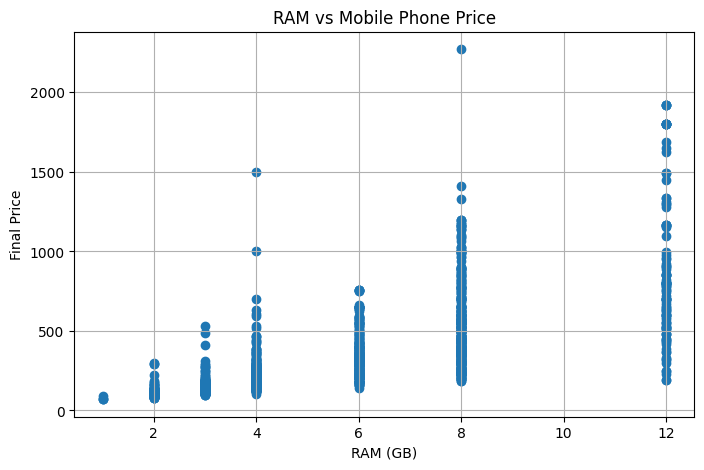

In [122]:
plt.figure(figsize=(8, 5))

plt.scatter(df['RAM'], df['Final Price'])

plt.xlabel('RAM (GB)')
plt.ylabel('Final Price')
plt.title('RAM vs Mobile Phone Price')

plt.grid(True)
plt.show()

In [123]:
X = df[['RAM']]
y = df['Final Price']

print("Input (X):")
print(X.head())

print("\nOutput (y):")
print(y.head())

Input (X):
    RAM
0   8.0
1   4.0
2   4.0
3   6.0
4  12.0

Output (y):
0    231.60
1    279.00
2    179.01
3    279.99
4    799.00
Name: Final Price, dtype: float64


In [124]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1066, 1)
Testing data: (267, 1)


In [125]:
model = LinearRegression()

print("Linear Regression model created successfully!")

Linear Regression model created successfully!


In [126]:
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [127]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 77.95459524373696
Intercept: -79.43388246000706


In [128]:
y_pred = model.predict(X_test)

print("Predictions completed successfully!")
print(y_pred[:10])

Predictions completed successfully!
[232.38449851 544.20287949 232.38449851 856.02126046 232.38449851
 232.38449851 232.38449851 388.293689   544.20287949 232.38449851]


In [129]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values[:10],
    'Predicted Price': y_pred[:10]
})

print(comparison)

   Actual Price  Predicted Price
0        159.88       232.384499
1        376.77       544.202879
2        308.96       232.384499
3       1451.00       856.021260
4        179.00       232.384499
5        199.95       232.384499
6        144.95       232.384499
7        499.00       388.293689
8        229.00       544.202879
9        165.99       232.384499


In [130]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("--------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
--------------------
MAE: 118.27144744220651
MSE: 28086.830556302884
RMSE: 167.59126038162876
R2 Score: 0.5579400653028651


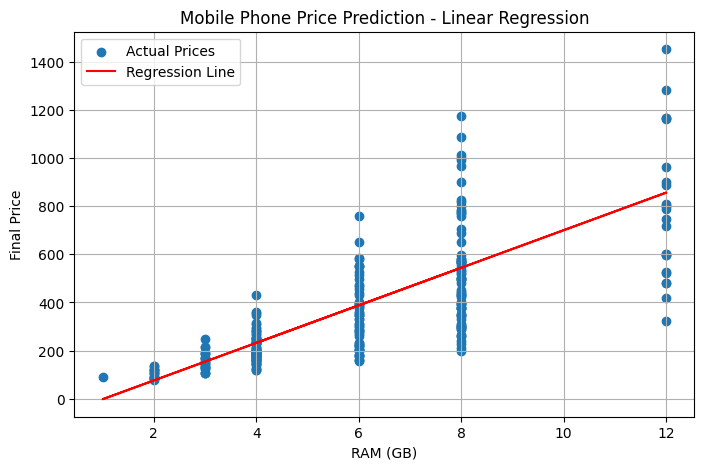

In [131]:
plt.figure(figsize=(8, 5))

plt.scatter(X_test['RAM'], y_test, label='Actual Prices')

plt.plot(X_test['RAM'], y_pred, color='red', label='Regression Line')

plt.xlabel('RAM (GB)')
plt.ylabel('Final Price')
plt.title('Mobile Phone Price Prediction - Linear Regression')

plt.legend()
plt.grid(True)

plt.show()

In [132]:
new_phone = pd.DataFrame({'RAM': [8]})

predicted_price = model.predict(new_phone)

print("RAM: 8 GB")
print("Predicted Mobile Price:", predicted_price[0])

RAM: 8 GB
Predicted Mobile Price: 544.2028794898886
